# RetailPulse — Étape 10 : tests de résilience et mesures de performance

Ce notebook rejoue, **cellule par cellule et commenté**, les sections 12, 13 et 14 du cahier des charges :

| Partie | Cahier | Contenu |
|---|---|---|
| A | §13 | 7 scénarios : flux nominal, paiement échoué, doublon, reprise Spark, PostgreSQL indisponible, événement tardif, Pod supprimé |
| B | §12 | traçabilité des messages invalides, idempotence du stockage des agrégats |
| C | §14 | 2 expériences de performance (débit, ressources Spark) + 1 facultative (partitions) : débit, latence, CPU/RAM |

**Principe de fiabilité des tests** : on ne se fie pas à Spark pour juger Spark. `tests/check_pipeline.py`
relit tout Kafka, recalcule le résultat attendu de façon indépendante, puis le compare à PostgreSQL.

**Prérequis**
1. Docker Desktop lancé et la pile démarrée : `docker compose up -d` (depuis la racine du dépôt).
2. Pour des tests rapides, Spark doit avoir un trigger court : `SPARK_TRIGGER_INTERVAL=10 seconds` (dans `.env` ou dans le shell
   avant `docker compose up -d`). Le notebook lit la valeur réelle et adapte ses attentes.
3. Python avec `pandas` et `matplotlib`. Aucun accès direct à Kafka/PostgreSQL depuis Python : tout passe par `docker exec`.

⚠️ Les scénarios modifient les données (messages invalides, événement tardif…). Pour repartir propre : `docker compose down -v && docker compose up -d --build`.

## 0. Préparation : outils communs

In [19]:
import io, json, os, re, subprocess, time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Racine du dépôt : le notebook est dans tests/, les commandes docker compose se lancent depuis la racine.
REPO = Path.cwd().resolve()
if REPO.name == "tests":
    REPO = REPO.parent
os.chdir(REPO)

# --- Réglages -------------------------------------------------------------------------------------
RUN_K8S = False          # True : exécute aussi "Pod supprimé" (minikube démarré, stack Compose arrêté)
RUN_PARTITIONS = False   # True : expérience 3 (augmente les partitions Kafka, IRRÉVERSIBLE sans 'down -v')
WARMUP = 120             # secondes de stabilisation avant chaque mesure (cahier : mesures reproductibles)
WINDOW = 120             # durée de la fenêtre de mesure, en secondes
ORDERS, EVENTS = "retail-orders", "retail-order-events"

RESULTS = []             # un enregistrement par scénario, rempli par report()


def run(args, input=None, env=None, timeout=600):
    # Lance une commande sans shell (pas de souci de guillemets Windows) et renvoie (code, sortie).
    full_env = {**os.environ, "MSYS_NO_PATHCONV": "1", **(env or {})}
    p = subprocess.run(args, input=input, capture_output=True, text=True, encoding="utf-8",
                       errors="replace", env=full_env, timeout=timeout)
    return p.returncode, (p.stdout + p.stderr).strip()


def compose(*args, **env_vars):
    # docker compose <args> ; les variables passées en argument surchargent le fichier .env
    return run(["docker", "compose", *args], env={k: str(v) for k, v in env_vars.items()})


def sql(query):
    # Exécute une requête dans PostgreSQL (via le conteneur) et renvoie un DataFrame.
    code_, out = run(["docker", "exec", "-i", "retailpulse-postgres", "sh", "-c",
                      'psql -v ON_ERROR_STOP=1 -U "$POSTGRES_USER" -d "$POSTGRES_DB" --csv'], input=query)
    if code_:
        raise RuntimeError(out)
    return pd.read_csv(io.StringIO(out))


def scalar(query):
    value = sql(query).iloc[0, 0]
    return float(value) if pd.notna(value) else 0.0


def send(lines):
    # Publie des lignes 'clé|json' dans retail-order-events (comme un producteur externe).
    return run(["docker", "exec", "-i", "retailpulse-kafka", "/opt/kafka/bin/kafka-console-producer.sh",
                "--bootstrap-server", "kafka:29092", "--topic", EVENTS,
                "--property", "parse.key=true", "--property", "key.separator=|"],
               input="\n".join(lines) + "\n")


def check():
    # Contrôle d'intégrité indépendant de Spark : renvoie True si tout est identique.
    code_, out = compose("run", "--rm", "--no-deps", "-v", "./tests:/tests",
                         "--entrypoint", "python", "simulator", "/tests/check_pipeline.py")
    print(out)
    return code_ == 0


def container_env(name, key, default=None):
    _, out = run(["docker", "inspect", name, "--format", "{{range .Config.Env}}{{println .}}{{end}}"])
    match = re.search(rf"^{key}=(.*)$", out, re.M)
    return match.group(1) if match else default


def trigger_seconds():
    # Intervalle de micro-batch de Spark, converti en secondes ('10 seconds' ou '5 minutes').
    value, unit = (container_env("retailpulse-spark", "TRIGGER_INTERVAL", "10 seconds") + " seconds").split()[:2]
    return int(float(value)) * (60 if unit.startswith("minute") else 1)


def wait_healthy(name, timeout=300):
    t0 = time.time()
    while time.time() - t0 < timeout:
        _, state = run(["docker", "inspect", name, "--format", "{{if .State.Health}}{{.State.Health.Status}}{{else}}{{.State.Status}}{{end}}"])
        if state in ("healthy", "running"):
            return round(time.time() - t0, 1)
        time.sleep(3)
    raise TimeoutError(name)


def kafka_end(topic):
    # Nombre total de messages écrits dans un topic (somme des fins de partitions).
    _, out = run(["docker", "exec", "retailpulse-kafka", "/opt/kafka/bin/kafka-get-offsets.sh",
                  "--bootstrap-server", "kafka:29092", "--topic", topic])
    return sum(int(line.split(":")[2]) for line in out.splitlines() if line.count(":") == 2)


def lag():
    # Retard de Spark = messages Kafka non encore lus d'après le dernier offset du checkpoint 'aggregates'.
    _, out = run(["docker", "exec", "retailpulse-spark", "sh", "-c",
                  "f=$(ls /checkpoints/aggregates/offsets | sort -n | tail -1); tail -1 /checkpoints/aggregates/offsets/$f"])
    position = json.loads(out.splitlines()[-1])
    return sum(kafka_end(t) - sum(position.get(t, {}).values()) for t in (ORDERS, EVENTS))


def settle(extra=15):
    # Laisse à Spark le temps de finir le micro-batch en cours (trigger + marge).
    time.sleep(trigger_seconds() + extra)


def wait_drained(timeout=600, tolerance=20):
    # Attend que Spark ait rattrapé Kafka (utile après une charge forte).
    t0 = time.time()
    while time.time() - t0 < timeout:
        try:
            if lag() <= tolerance:
                break
        except Exception:
            pass
        time.sleep(10)
    settle()


def report(scenario, ok, detail):
    RESULTS.append({"Scénario": scenario, "Résultat": "OK" if ok else "ÉCART", "Détail": detail})
    print(("✅" if ok else "❌"), scenario, "-", detail)


# Début de la période de test : mémorisé dans un fichier pour survivre à un redémarrage du noyau.
# Tout ce qui est écrit dans PostgreSQL après cet instant pourra être purgé à la fin (section "Purge").
PERIOD_FILE = REPO / "tests" / ".test_period.json"
if PERIOD_FILE.exists():
    TEST_START = json.loads(PERIOD_FILE.read_text())["start"]
else:
    TEST_START = sql("SELECT now() AS t").t[0]
    PERIOD_FILE.write_text(json.dumps({"start": TEST_START}))

print("Dépôt :", REPO)
print("Début de la période de test :", TEST_START)
print("Trigger Spark :", trigger_seconds(), "s")
print(run(["docker", "ps", "--format", "{{.Names}}  {{.Status}}"])[1])

Dépôt : C:\Users\Asus\Desktop\Données Distribuées\TP5\cours_séance_5_et_projet_\tp-kafka-python-json
Début de la période de test : 2026-11-04 15:04:37.651544+00
Trigger Spark : 10 s
retailpulse-simulator  Up 47 minutes
retailpulse-dashboard  Up 2 hours (healthy)
retailpulse-spark  Up About an hour (healthy)
retailpulse-kafka  Up 7 hours (healthy)
retailpulse-postgres  Up About an hour (healthy)
minikube  Up 6 hours


# Partie A — Scénarios de résilience (cahier §13)

Chaque scénario suit le même schéma : **état avant → manipulation → état après → verdict**.
Un scénario sans verdict chiffré ne prouve rien : les résultats attendus sont donc vérifiés par du code.

| # | Ce que l'on teste (en une phrase) | Preuve attendue |
|---|---|---|
| A1 | La chaîne complète fonctionne de bout en bout | PostgreSQL = ce que Kafka contient |
| A2 | Un paiement échoué ne compte pas dans le chiffre d'affaires | CA inchangé, 10 commandes `FAILED` |
| A3 | Un événement publié deux fois n'est compté qu'une fois | Contrôle `OK` malgré 10 doublons dans Kafka |
| A4 | Spark redémarré reprend sans perte ni double comptage | CA identique avant/après |
| A5 | Une panne de PostgreSQL ne fait perdre aucune donnée | Contrôle `OK` après rétablissement |
| A6 | Un événement un peu en retard est accepté, un très ancien est refusé | CA +99,90 $ exactement |
| A7 | Kubernetes recrée un Pod supprimé, données conservées | Pod prêt en moins de 5 min, PVC intacts |
| B1 | Les messages invalides sont tracés, pas perdus ni fatals | 3 lignes dans `invalid_events` |
| B2 | Réécrire un agrégat plusieurs fois ne le modifie pas | Même nombre de lignes, même somme, même empreinte |

## A1. Flux nominal
**🎯 Ce que l'on teste :** Que la chaîne complète fonctionne de bout en bout : simulateur → Kafka → Spark → PostgreSQL, avec des résultats identiques à ce que Kafka contient.

**Manipulation** : démarrer la pile (déjà fait) et laisser le simulateur produire une minute.
**Attendu** : les messages circulent dans Kafka, les agrégats apparaissent dans PostgreSQL, et PostgreSQL = ce que Kafka permet d'attendre.

In [20]:
compose("up", "-d", "--no-deps", "simulator")
n0 = scalar("SELECT count(*) FROM orders WHERE status <> 'CREATED'")
k0 = kafka_end(EVENTS)
time.sleep(60)
n1 = scalar("SELECT count(*) FROM orders WHERE status <> 'CREATED'")
k1 = kafka_end(EVENTS)
aggregates = scalar("SELECT count(*) FROM sales_aggregates")

compose("stop", "simulator")   # on fige la production avant de comparer Kafka et PostgreSQL
settle()
identical = check()
report("A1 Flux nominal", n1 > n0 and aggregates > 0 and identical,
       f"+{int(k1-k0)} événements Kafka en 60 s, +{int(n1-n0)} commandes traitées, "
       f"{int(aggregates)} agrégats, contrôle Kafka/PostgreSQL identique={identical}")

Container retailpulse-simulator-run-7cce12721a86 Creating 
 Container retailpulse-simulator-run-7cce12721a86 Created 
Traceback (most recent call last):
  File "/tests/check_pipeline.py", line 100, in <module>
    main()
  File "/tests/check_pipeline.py", line 61, in main
    expected_revenue = round(sum(i["quantity"] * i["unit_price"]
                             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tests/check_pipeline.py", line 62, in <genexpr>
    for e in completed for i in e["items"]), 2)
                                ~^^^^^^^^^
KeyError: 'items'
❌ A1 Flux nominal - +61 événements Kafka en 60 s, +66 commandes traitées, 2879 agrégats, contrôle Kafka/PostgreSQL identique=False


## A2. Paiement échoué
**🎯 Ce que l'on teste :** Qu'un paiement refusé ne gonfle jamais le chiffre d'affaires : seul `PAYMENT_COMPLETED` doit compter.

**Manipulation** : 10 commandes dont **100 % échouent** (`FAILURE_RATE=1`).
**Attendu** : 10 commandes passent à `FAILED` mais le chiffre d'affaires **ne bouge pas** (seul `PAYMENT_COMPLETED` compte).

In [21]:
revenue0 = scalar("SELECT coalesce(sum(total_revenue),0) FROM sales_aggregates")
failed0 = scalar("SELECT count(*) FROM orders WHERE status = 'FAILED'")
compose("run", "--rm", "--no-deps", "-e", "MAX_ORDERS=10", "-e", "FAILURE_RATE=1", "-e", "CANCEL_RATE=0", "simulator")
settle()
revenue1 = scalar("SELECT coalesce(sum(total_revenue),0) FROM sales_aggregates")
failed1 = scalar("SELECT count(*) FROM orders WHERE status = 'FAILED'")
report("A2 Paiement échoué", round(revenue1 - revenue0, 2) == 0 and failed1 - failed0 == 10,
       f"CA {revenue0:.2f} -> {revenue1:.2f} (écart {revenue1-revenue0:.2f}) ; FAILED +{int(failed1-failed0)}")

✅ A2 Paiement échoué - CA 411928107.54 -> 411928107.54 (écart 0.00) ; FAILED +10


## A3. Doublon (même `event_id` publié deux fois)
**🎯 Ce que l'on teste :** Qu'un même événement reçu deux fois n'est compté qu'une seule fois (règle métier : un paiement = un encaissement).

**Manipulation** : 10 commandes, chaque paiement est republié à l'identique (`DUPLICATE_RATE=1`).
**Attendu** : Kafka contient les doublons (il transporte, il ne déduplique pas) mais PostgreSQL ne compte chaque paiement qu'une fois :
c'est `dropDuplicatesWithinWatermark(event_id)` qui en répond. Le contrôle indépendant doit rester `OK`.

In [22]:
compose("run", "--rm", "--no-deps", "-e", "MAX_ORDERS=10", "-e", "DUPLICATE_RATE=1", "simulator")
settle()
identical = check()    # la 1re ligne de la sortie annonce le nombre de doublons trouvés dans Kafka
report("A3 Doublon", identical, "10 paiements publiés deux fois ; chaque event_id compté une seule fois" if identical else "écart : voir la sortie")

Container retailpulse-simulator-run-dfca08422bf5 Creating 
 Container retailpulse-simulator-run-dfca08422bf5 Created 
Traceback (most recent call last):
  File "/tests/check_pipeline.py", line 100, in <module>
    main()
  File "/tests/check_pipeline.py", line 61, in main
    expected_revenue = round(sum(i["quantity"] * i["unit_price"]
                             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tests/check_pipeline.py", line 62, in <genexpr>
    for e in completed for i in e["items"]), 2)
                                ~^^^^^^^^^
KeyError: 'items'
❌ A3 Doublon - écart : voir la sortie


## A4. Reprise de Spark avec checkpoint
**🎯 Ce que l'on teste :** Que Spark, redémarré brutalement, reprend là où il s'était arrêté, sans perdre ni recompter de données.

**Manipulation** : redémarrer le conteneur Spark (`docker compose restart spark`).
**Attendu** : le checkpoint conserve les offsets Kafka **et** l'état (déduplication, agrégats) : Spark reprend où il s'est arrêté,
le chiffre d'affaires est identique avant/après, aucun double comptage.

*Limite à connaître* : la garantie est « au moins une fois » côté lecture ; c'est l'**écriture idempotente** (upsert qui remplace) qui évite le double comptage, pas Spark seul.

In [23]:
revenue0 = scalar("SELECT coalesce(sum(total_revenue),0) FROM sales_aggregates")
orders0 = scalar("SELECT count(*) FROM orders")
print("Dernière position du checkpoint :", run(["docker", "exec", "retailpulse-spark", "sh", "-c",
      "f=$(ls /checkpoints/aggregates/offsets | sort -n | tail -1); tail -1 /checkpoints/aggregates/offsets/$f"])[1])

compose("restart", "spark")
print("Spark de nouveau healthy après", wait_healthy("retailpulse-spark"), "s")
settle(45)

revenue1 = scalar("SELECT coalesce(sum(total_revenue),0) FROM sales_aggregates")
orders1 = scalar("SELECT count(*) FROM orders")
print(compose("logs", "--since", "90s", "spark")[1][-1500:])   # aucun gros retraitement attendu
identical = check()
report("A4 Reprise Spark", revenue1 == revenue0 and orders1 == orders0 and identical,
       f"CA {revenue0:.2f} -> {revenue1:.2f}, commandes {int(orders0)} -> {int(orders1)}")

Dernière position du checkpoint : {"retail-order-events":{"2":20721,"1":20597,"0":20524},"retail-orders":{"2":20715,"1":20591,"0":20511}}
Spark de nouveau healthy après 22.6 s
ger BlockManagerId(driver, 692302323ff8, 33181, None)
retailpulse-spark  | 26/11/04 15:08:40 INFO BlockManager: Initialized BlockManager: BlockManagerId(driver, 692302323ff8, 33181, None)
retailpulse-spark  | 26/11/04 15:08:58 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
retailpulse-spark  | 26/11/04 15:08:58 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
retailpulse-spark  | 26/11/04 15:08:58 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
retailpulse-spark  | 2026-11-04 15:08:58,820 INFO spark 3 requêtes démarrées (fenêtre 5 minutes, watermark 10 minutes, trigger 10 seconds, ch

## A5. PostgreSQL indisponible
**🎯 Ce que l'on teste :** Que la panne de la base ne fait perdre aucune donnée : Kafka garde les messages et Spark les rejoue une fois la base revenue.

**Manipulation** : simulateur actif, arrêt de PostgreSQL pendant 1 minute, puis rétablissement.
**Attendu** : Spark échoue pendant la coupure (écritures impossibles) et est relancé par Docker (`restart: unless-stopped`) ;
le tableau de bord affiche un message d'erreur sans planter. Après rétablissement Spark **rattrape** son retard depuis Kafka
(Kafka sert de tampon) : aucune perte, aucun double comptage (contrôle `OK`).

*Pourquoi ça marche* : un micro-batch qui échoue n'est **pas** validé dans le checkpoint, il est donc rejoué ; l'upsert rend le rejeu inoffensif.

In [24]:
compose("up", "-d", "--no-deps", "simulator")
time.sleep(20)
compose("stop", "postgres")
time.sleep(60)
print("Pendant la coupure :")
print(run(["docker", "ps", "-a", "--format", "{{.Names}}  {{.Status}}", "--filter", "name=retailpulse-spark"])[1])
print("Redémarrages Spark :", run(["docker", "inspect", "retailpulse-spark", "--format", "{{.RestartCount}}"])[1])

compose("start", "postgres")
print("PostgreSQL de nouveau healthy après", wait_healthy("retailpulse-postgres"), "s")
time.sleep(120)                  # Spark redémarre puis traite l'arriéré
compose("stop", "simulator")
wait_drained()
identical = check()
report("A5 PostgreSQL indisponible", identical, "coupure 60 s ; reprise automatique, Kafka a servi de tampon ; aucun écart")

Pendant la coupure :
retailpulse-spark  Up 26 seconds (healthy)
Redémarrages Spark : 1
PostgreSQL de nouveau healthy après 6.7 s
Container retailpulse-simulator-run-8ab61816e6ac Creating 
 Container retailpulse-simulator-run-8ab61816e6ac Created 
Traceback (most recent call last):
  File "/tests/check_pipeline.py", line 100, in <module>
    main()
  File "/tests/check_pipeline.py", line 61, in main
    expected_revenue = round(sum(i["quantity"] * i["unit_price"]
                             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tests/check_pipeline.py", line 62, in <genexpr>
    for e in completed for i in e["items"]), 2)
                                ~^^^^^^^^^
KeyError: 'items'
❌ A5 PostgreSQL indisponible - coupure 60 s ; reprise automatique, Kafka a servi de tampon ; aucun écart


## A6. Événement tardif et watermark
**🎯 Ce que l'on teste :** Que Spark accepte un événement un peu en retard (3 min) mais refuse un événement trop ancien (30 min), conformément au watermark de 10 min.

**Contexte** : fenêtres de 5 min, watermark de 10 min. Le watermark suit l'événement **le plus récent** vu par Spark.
**Manipulation** : on amène le watermark à l'heure actuelle (30 s de simulation), puis on publie deux paiements anciens de 10 × 9,99 $ (retard 3 min) et 7 × 9,99 $ (retard 30 min).
**Attendu** : le retard de 3 min est **intégré** (+99,90 $), celui de 30 min est **ignoré** (> watermark). Comportement documenté, pas un bug.

⚠️ Ce scénario fausse volontairement `check_pipeline.py` (il verra un paiement que Spark a ignoré) : le faire en dernier, ou remettre à zéro ensuite.

In [25]:
from datetime import datetime, timedelta, timezone

def late_event(minutes_late, quantity):
    stamp = (datetime.now(timezone.utc) - timedelta(minutes=minutes_late)).strftime("%Y-%m-%dT%H:%M:%S.000Z")
    order_id = f"ORD-LATE-{minutes_late}-{int(time.time())}"
    event = {"event_id": f"late-{minutes_late}-{int(time.time())}", "event_type": "PAYMENT_COMPLETED",
             "event_timestamp": stamp, "order_id": order_id, "customer_id": 1,
             "items": [{"product_id": 1, "quantity": quantity, "unit_price": 9.99}], "amount": 0, "currency": "USD"}
    return f"{order_id}|{json.dumps(event)}"

compose("up", "-d", "--no-deps", "simulator"); time.sleep(30); compose("stop", "simulator"); settle()
before = scalar("SELECT coalesce(sum(total_revenue),0) FROM sales_aggregates")
send([late_event(3, 10), late_event(30, 7)])
settle()
after = scalar("SELECT coalesce(sum(total_revenue),0) FROM sales_aggregates")
delta = round(after - before, 2)
report("A6 Événement tardif", delta == 99.90,
       f"CA +{delta} $ (attendu 99,90 : le retard de 3 min compte, celui de 30 min est écarté par le watermark)")

✅ A6 Événement tardif - CA +99.9 $ (attendu 99,90 : le retard de 3 min compte, celui de 30 min est écarté par le watermark)


## A7. Pod indisponible (Kubernetes) — facultatif ici
**🎯 Ce que l'on teste :** Que Kubernetes remet en route un composant supprimé tout seul, sans perte de données (grâce aux volumes persistants), et en combien de temps.

**Prérequis** : `minikube start`, pile Compose arrêtée (`docker compose down`, sans `-v`), `bash k8s/deploy.sh` déjà exécuté, puis `RUN_K8S = True` dans la cellule 0.
**Manipulation** : supprimer un Pod de chaque contrôleur (Deployment `spark`, StatefulSets `postgres` et `kafka`).
**Attendu** : le contrôleur recrée le Pod ; les données survivent grâce aux PVC ; on **mesure** la durée d'indisponibilité et on analyse l'impact
(Spark = `Recreate` car un seul processus peut écrire dans le checkpoint ; Kafka/PostgreSQL = identité stable + volume).
Mesures déjà obtenues sur ce projet : `docs/deploiement-kubernetes.md`.

In [26]:
if not RUN_K8S:
    print("Cellule ignorée (RUN_K8S = False). Résultats antérieurs : docs/deploiement-kubernetes.md")
else:
    rows = []
    for app in ("spark", "postgres", "kafka"):
        selector = f"app.kubernetes.io/name={app}"
        t0 = time.time()
        run(["kubectl", "-n", "retailpulse", "delete", "pod", "-l", selector])           # attend la disparition du Pod
        _, out = run(["kubectl", "-n", "retailpulse", "wait", "--for=condition=Ready", "pod", "-l", selector, "--timeout=300s"])
        rows.append({"Pod supprimé": app, "Recréé et prêt en (s)": round(time.time() - t0, 1), "kubectl": out.splitlines()[-1]})
    display(pd.DataFrame(rows))
    print(run(["kubectl", "-n", "retailpulse", "get", "pods"])[1])
    report("A7 Pod indisponible", all(r["Recréé et prêt en (s)"] < 300 for r in rows), "voir tableau ci-dessus")

Cellule ignorée (RUN_K8S = False). Résultats antérieurs : docs/deploiement-kubernetes.md


# Partie B — Fiabilité et cohérence (cahier §12)

> « Aucun mécanisme isolé ne garantit l'absence de doublons de bout en bout. »

| Brique | Ce qu'elle garantit | Ce qu'elle ne garantit pas |
|---|---|---|
| Kafka (producteur `acks=all`, idempotent) | Pas de perte ni de doublon *dû aux retries du producteur*, ordre par partition (clé `order_id`) | Ne déduplique pas deux publications distinctes du même `event_id` ; 1 broker, RF=1 → pas de tolérance à la perte du disque |
| Spark + checkpoint | Reprise aux derniers offsets validés, état conservé | Lecture « au moins une fois » : un batch peut être rejoué |
| Déduplication `event_id` | Un doublon arrivé dans le watermark est ignoré | Un doublon après le watermark n'est plus reconnu (mais l'événement serait déjà tardif) |
| PostgreSQL (clé primaire + `ON CONFLICT`) | Écriture **idempotente** : rejouer remplace au lieu d'additionner | — |
| Kubernetes | Recrée les Pods, conserve les PVC | Ne répare pas la cohérence des données |

**Identifiants** : `event_id` = un événement (clé de déduplication) ; `order_id` = une commande (relie création et paiement, clé Kafka) ;
`product_id` / `customer_id` = identifiants du référentiel DummyJSON.

## B1. Traçabilité des événements invalides
**🎯 Ce que l'on teste :** Que les messages cassés ou incohérents ne font pas planter Spark et ne sont pas perdus en silence : ils sont enregistrés avec leur raison.

**Manipulation** : publier un texte non JSON, un événement incomplet, un type inconnu (`REFUND`).
**Attendu** : 3 lignes dans `invalid_events` avec leur raison, aucune influence sur le chiffre d'affaires.

In [27]:
revenue0 = scalar("SELECT coalesce(sum(total_revenue),0) FROM sales_aggregates")
invalid0 = scalar("SELECT count(*) FROM invalid_events")
stamp = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.000Z")
send([
    "k1|ceci nest pas du json",
    'k2|{"event_id":"x1","event_type":"PAYMENT_COMPLETED"}',
    'k3|{"event_id":"x2","event_type":"REFUND","event_timestamp":"%s","order_id":"o","customer_id":1,'
    '"items":[{"product_id":1,"quantity":1,"unit_price":1}],"amount":1}' % stamp,
])
settle()
revenue1 = scalar("SELECT coalesce(sum(total_revenue),0) FROM sales_aggregates")
display(sql("SELECT reason, count(*) AS n FROM invalid_events GROUP BY reason ORDER BY reason"))
invalid1 = scalar("SELECT count(*) FROM invalid_events")
report("B1 Événements invalides tracés", invalid1 - invalid0 == 3 and revenue1 == revenue0,
       f"+{int(invalid1-invalid0)} lignes dans invalid_events, CA inchangé")

,reason,n
0,json_invalide_ou_champ_manquant,4
1,type_inattendu,2


✅ B1 Événements invalides tracés - +3 lignes dans invalid_events, CA inchangé


## B2. Idempotence du stockage des agrégats
**🎯 Ce que l'on teste :** Que réécrire plusieurs fois le même agrégat dans PostgreSQL donne toujours le même résultat (rejouer ne double jamais le chiffre d'affaires).

**Idée** : l'upsert *remplace* les valeurs (`SET total_revenue = EXCLUDED.total_revenue`) au lieu de les additionner.
**Manipulation** : on rejoue **deux fois** exactement la requête d'upsert de Spark avec les valeurs déjà stockées.
**Attendu** : nombre de lignes, somme et empreinte MD5 de la table identiques. Un upsert « additif » (`+ EXCLUDED…`) aurait doublé le CA à chaque rejeu.

In [28]:
FINGERPRINT = '''
SELECT count(*) AS lignes, sum(total_revenue) AS ca, sum(order_count) AS commandes,
       md5(string_agg(category || window_start || window_end || order_count || total_quantity || total_revenue,
                      ',' ORDER BY category, window_start, window_end)) AS empreinte
FROM sales_aggregates'''
REPLAY = '''
INSERT INTO sales_aggregates (category, window_start, window_end, order_count, total_quantity, total_revenue)
SELECT category, window_start, window_end, order_count, total_quantity, total_revenue FROM sales_aggregates
ON CONFLICT (category, window_start, window_end) DO UPDATE SET
    order_count = EXCLUDED.order_count, total_quantity = EXCLUDED.total_quantity,
    total_revenue = EXCLUDED.total_revenue, updated_at = now()'''

compose("stop", "simulator"); settle()
snapshots = [sql(FINGERPRINT)]
for _ in range(2):
    code_, out = run(["docker", "exec", "-i", "retailpulse-postgres", "sh", "-c",
                      'psql -v ON_ERROR_STOP=1 -U "$POSTGRES_USER" -d "$POSTGRES_DB"'], input=REPLAY)
    assert code_ == 0, out
    snapshots.append(sql(FINGERPRINT))
display(pd.concat(snapshots, keys=["avant", "après 1 rejeu", "après 2 rejeux"]))
same = all(s.equals(snapshots[0]) for s in snapshots)
report("B2 Idempotence des agrégats", same, "même nombre de lignes, même CA, même empreinte après 2 rejeux")

,,lignes,ca,commandes,empreinte
avant,0,2903,4.134157e+08,123075,8f1ada9325cfd3686ae7bc696e31cc50
après 1 rejeu,0,2903,4.134157e+08,123075,8f1ada9325cfd3686ae7bc696e31cc50
après 2 rejeux,0,2903,4.134157e+08,123075,8f1ada9325cfd3686ae7bc696e31cc50


✅ B2 Idempotence des agrégats - même nombre de lignes, même CA, même empreinte après 2 rejeux


### Synthèse des scénarios

In [29]:
summary = pd.DataFrame(RESULTS)
display(summary)
print("Tous les scénarios sont OK." if (summary["Résultat"] == "OK").all() else "Des écarts sont à analyser.")

,Scénario,Résultat,Détail
0,A1 Flux nominal,ÉCART,"+61 événements Kafka en 60 s, +66 commandes tr..."
1,A2 Paiement échoué,OK,CA 411928107.54 -> 411928107.54 (écart 0.00) ;...
2,A3 Doublon,ÉCART,écart : voir la sortie
3,A4 Reprise Spark,ÉCART,"CA 412069731.28 -> 412069731.28, commandes 618..."
4,A5 PostgreSQL indisponible,ÉCART,"coupure 60 s ; reprise automatique, Kafka a se..."
5,A6 Événement tardif,OK,"CA +99.9 $ (attendu 99,90 : le retard de 3 min..."
6,B1 Événements invalides tracés,OK,"+3 lignes dans invalid_events, CA inchangé"
7,B2 Idempotence des agrégats,OK,"même nombre de lignes, même CA, même empreinte..."


Des écarts sont à analyser.


# Partie C — Mesure des performances (cahier §14)

**Au minimum deux expériences**, reproductibles, interprétées. Ici :

| Expérience | Variable qui change | Configurations |
|---|---|---|
| 1 | Débit de production | A : ~0,8 commande/s (défaut) — B : charge élevée (intervalle 0,01–0,02 s) |
| 2 | Ressources CPU de Spark | B (Spark sans limite) — B + Spark limité à 1 CPU |
| 3 (facultative) | Partitions Kafka | B avec 6 partitions au lieu de 3 |

## Méthodes de mesure (à citer dans le rapport)
- **Débit produit** = Δ du nombre de messages dans Kafka (`kafka-get-offsets`) ÷ durée de la fenêtre.
- **Débit traité** = (Δ commandes créées + Δ commandes dont le statut a été écrit) ÷ durée. Chaque commande = 2 événements traités par Spark.
- **Retard (lag)** en fin de fenêtre = messages Kafka − position du checkpoint Spark. Un lag qui croît = Spark saturé.
- **Latence de bout en bout** = `orders.updated_at − orders.created_at` (heure d'écriture par Spark − heure d'émission dans l'événement).
  Même horloge pour tous les conteneurs. Elle inclut le délai simulé de 0,1–0,9 s entre commande et paiement et l'attente du trigger de Spark.
  On ne regarde que les commandes **créées pendant la fenêtre** ; celles encore en attente sont comptées à part pour ne pas masquer la saturation.
- **CPU / RAM** = moyenne de 3 relevés `docker stats --no-stream`.
- Pour la **visibilité sur le tableau de bord**, ajouter jusqu'à `REFRESH_SECONDS` à la latence.

In [30]:
def to_mib(text):
    number, unit = re.match(r"([\d.]+)\s*([KMG]i?B)", text).groups()
    return float(number) * {"KB": 1/1024, "KiB": 1/1024, "MB": 1, "MiB": 1, "GB": 1024, "GiB": 1024}[unit]


def docker_stats(samples=3, pause=5):
    rows = []
    for _ in range(samples):
        _, out = run(["docker", "stats", "--no-stream", "--format", "{{.Name}};{{.CPUPerc}};{{.MemUsage}}"])
        for line in out.splitlines():
            name, cpu, mem = line.split(";")
            rows.append({"name": name, "cpu": float(cpu.strip("%")), "mem_mib": to_mib(mem.split("/")[0].strip())})
        time.sleep(pause)
    return pd.DataFrame(rows).groupby("name")[["cpu", "mem_mib"]].mean()


def measure(config):
    # Une mesure complète : stabilisation, fenêtre, débit, lag, latence, ressources.
    print(f"[{config}] stabilisation {WARMUP} s…")
    time.sleep(WARMUP)
    t0 = sql("SELECT now() AS t").t[0]
    produced0 = kafka_end(ORDERS) + kafka_end(EVENTS)
    created0 = scalar("SELECT count(*) FROM orders")
    paid0 = scalar("SELECT count(*) FROM orders WHERE status <> 'CREATED'")
    started = time.time()

    stats = docker_stats()                    # 3 relevés pendant la fenêtre (~15 s)
    time.sleep(max(0, WINDOW - (time.time() - started)))
    duration = time.time() - started

    produced1 = kafka_end(ORDERS) + kafka_end(EVENTS)
    created1 = scalar("SELECT count(*) FROM orders")
    paid1 = scalar("SELECT count(*) FROM orders WHERE status <> 'CREATED'")
    latency = sql(f'''
        SELECT count(*) FILTER (WHERE status <> 'CREATED') AS traitees,
               count(*) FILTER (WHERE status = 'CREATED')  AS en_attente,
               round((percentile_cont(0.5)  WITHIN GROUP (ORDER BY extract(epoch FROM updated_at - created_at))
                      FILTER (WHERE status <> 'CREATED'))::numeric, 1) AS p50_s,
               round((percentile_cont(0.95) WITHIN GROUP (ORDER BY extract(epoch FROM updated_at - created_at))
                      FILTER (WHERE status <> 'CREATED'))::numeric, 1) AS p95_s
        FROM orders WHERE created_at >= '{t0}' ''').iloc[0]
    return {
        "Config": config,
        "Débit produit (évt/s)": round((produced1 - produced0) / duration, 1),
        "Débit traité (évt/s)": round(((created1 - created0) + (paid1 - paid0)) / duration, 1),
        "Lag fin (msgs)": lag(),
        "Latence p50 (s)": float(latency.p50_s),
        "Latence p95 (s)": float(latency.p95_s),
        "En attente": int(latency.en_attente),
        "Spark CPU %": round(stats.loc["retailpulse-spark", "cpu"], 1),
        "Spark RAM (MiB)": round(stats.loc["retailpulse-spark", "mem_mib"]),
        "Kafka CPU %": round(stats.loc["retailpulse-kafka", "cpu"], 1),
        "Kafka RAM (MiB)": round(stats.loc["retailpulse-kafka", "mem_mib"]),
        "Postgres CPU %": round(stats.loc["retailpulse-postgres", "cpu"], 1),
    }


PERF = []
print("Fonctions de mesure prêtes. Débit actuel de Spark :", container_env("retailpulse-spark", "TRIGGER_INTERVAL"))

Fonctions de mesure prêtes. Débit actuel de Spark : 10 seconds


## Expérience 1 — Débit de production (A → B)
**🎯 Ce que l'on teste :** Jusqu'à quel débit la chaîne tient la charge, et ce qui se passe (retard, latence) quand on dépasse sa capacité.

On relance **uniquement le simulateur** avec un autre rythme (les variables du shell priment sur `.env`).
Hypothèse à vérifier : tant que Spark traite autant que Kafka reçoit, le lag reste proche de 0 et la latence est dominée par le trigger ;
au-delà de sa capacité, le lag grandit et la latence explose.

In [31]:
# Config A : défaut (~0,8 commande/s)
compose("up", "-d", "--no-deps", "simulator", SIM_INTERVAL_MIN=0.5, SIM_INTERVAL_MAX=2.0)
PERF.append(measure("A — défaut (~0,8 cmd/s)"))
display(pd.DataFrame(PERF))

[A — défaut (~0,8 cmd/s)] stabilisation 120 s…


,Config,Débit produit (évt/s),Débit traité (évt/s),Lag fin (msgs),Latence p50 (s),Latence p95 (s),En attente,Spark CPU %,Spark RAM (MiB),Kafka CPU %,Kafka RAM (MiB),Postgres CPU %
0,"A — défaut (~0,8 cmd/s)",1.8,1.7,18,7.7,12.1,0,99.3,621,5.0,1064,3.1


In [32]:
# Config B : charge élevée (intervalle 0,01–0,02 s)
compose("up", "-d", "--no-deps", "simulator", SIM_INTERVAL_MIN=0.01, SIM_INTERVAL_MAX=0.02)
PERF.append(measure("B — charge élevée"))
display(pd.DataFrame(PERF))

[B — charge élevée] stabilisation 120 s…


,Config,Débit produit (évt/s),Débit traité (évt/s),Lag fin (msgs),Latence p50 (s),Latence p95 (s),En attente,Spark CPU %,Spark RAM (MiB),Kafka CPU %,Kafka RAM (MiB),Postgres CPU %
0,"A — défaut (~0,8 cmd/s)",1.8,1.7,18,7.7,12.1,0,99.3,621,5.0,1064,3.1
1,B — charge élevée,137.4,132.0,1711,8.3,12.9,0,104.6,637,81.5,1093,4.0


## Expérience 2 — Ressources CPU de Spark (B → B limité à 1 CPU)
**🎯 Ce que l'on teste :** Si Spark est le goulot d'étranglement : quel impact a la réduction de ses ressources CPU sur le débit et la latence ?

Spark tourne en `local[2]` (2 threads d'exécution). On le bride à 1 CPU **sans rien reconstruire** (`docker update`) et on garde la charge B.
On laisse d'abord Spark finir son arriéré pour partir d'un état comparable.

In [33]:
compose("stop", "simulator"); wait_drained()
run(["docker", "update", "--cpus", "1", "retailpulse-spark"])
compose("up", "-d", "--no-deps", "simulator", SIM_INTERVAL_MIN=0.01, SIM_INTERVAL_MAX=0.02)
PERF.append(measure("B + Spark limité à 1 CPU"))
display(pd.DataFrame(PERF))

# Retour à la normale
compose("stop", "simulator")
run(["docker", "update", "--cpus", "0", "retailpulse-spark"])   # 0 = pas de limite
wait_drained()

[B + Spark limité à 1 CPU] stabilisation 120 s…


,Config,Débit produit (évt/s),Débit traité (évt/s),Lag fin (msgs),Latence p50 (s),Latence p95 (s),En attente,Spark CPU %,Spark RAM (MiB),Kafka CPU %,Kafka RAM (MiB),Postgres CPU %
0,"A — défaut (~0,8 cmd/s)",1.8,1.7,18,7.7,12.1,0,99.3,621,5.0,1064,3.1
1,B — charge élevée,137.4,132.0,1711,8.3,12.9,0,104.6,637,81.5,1093,4.0
2,B + Spark limité à 1 CPU,135.7,131.6,2240,8.2,13.1,0,100.9,710,49.0,1112,19.8


## Expérience 3 (facultative) — Partitions Kafka (3 → 6)
**🎯 Ce que l'on teste :** Si ajouter des partitions Kafka accélère le traitement, ou si la limite se situe ailleurs (nombre de cœurs de Spark).

On ajoute des partitions aux deux topics d'événements (`kafka-topics.sh --alter`). Spark lit les nouvelles partitions sans toucher au checkpoint.
**Irréversible** : Kafka ne sait pas réduire un nombre de partitions (retour = `docker compose down -v`).
Hypothèse à discuter : Spark ne dispose que de 2 cœurs (`local[2]`) → plus de partitions ne devrait **pas** améliorer le débit (le goulot est ailleurs).
Activer avec `RUN_PARTITIONS = True`.

In [34]:
if not RUN_PARTITIONS:
    print("Cellule ignorée (RUN_PARTITIONS = False).")
else:
    for topic in (ORDERS, EVENTS):
        print(run(["docker", "exec", "retailpulse-kafka", "/opt/kafka/bin/kafka-topics.sh",
                   "--bootstrap-server", "kafka:29092", "--alter", "--topic", topic, "--partitions", "6"])[1])
    compose("up", "-d", "--no-deps", "simulator", SIM_INTERVAL_MIN=0.01, SIM_INTERVAL_MAX=0.02)
    PERF.append(measure("B + 6 partitions"))
    compose("stop", "simulator"); wait_drained()
    display(pd.DataFrame(PERF))

Cellule ignorée (RUN_PARTITIONS = False).


## Résultats : tableau et graphiques

,Débit produit (évt/s),Débit traité (évt/s),Lag fin (msgs),Latence p50 (s),Latence p95 (s),En attente,Spark CPU %,Spark RAM (MiB),Kafka CPU %,Kafka RAM (MiB),Postgres CPU %
Config,,,,,,,,,,,
"A — défaut (~0,8 cmd/s)",1.8,1.7,18,7.7,12.1,0,99.3,621,5.0,1064,3.1
B — charge élevée,137.4,132.0,1711,8.3,12.9,0,104.6,637,81.5,1093,4.0
B + Spark limité à 1 CPU,135.7,131.6,2240,8.2,13.1,0,100.9,710,49.0,1112,19.8


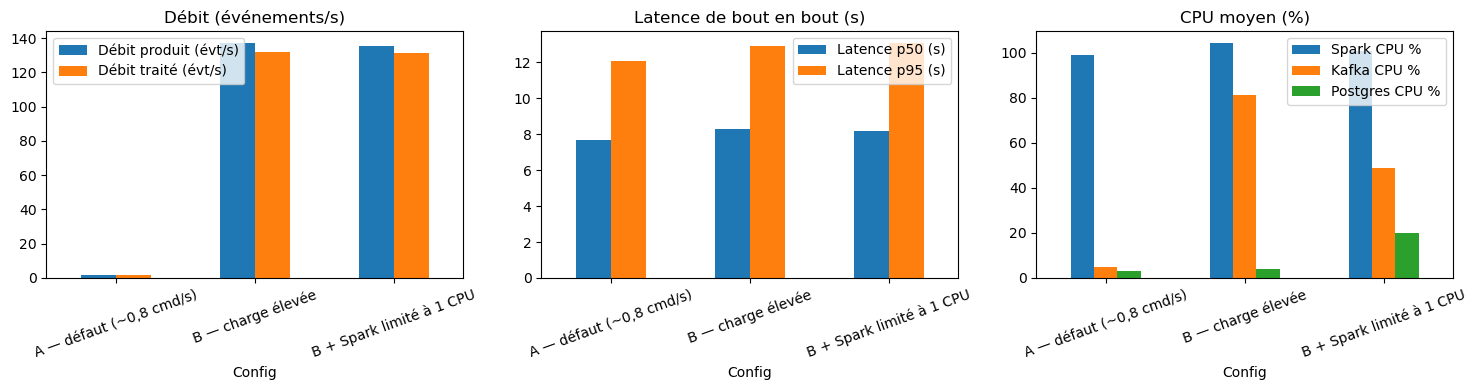

In [35]:
perf = pd.DataFrame(PERF).set_index("Config")
display(perf)
perf.to_csv(REPO / "docs" / "resultats-performance.csv", encoding="utf-8")   # trace brute pour le rapport

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
perf[["Débit produit (évt/s)", "Débit traité (évt/s)"]].plot.bar(ax=axes[0], rot=20, title="Débit (événements/s)")
perf[["Latence p50 (s)", "Latence p95 (s)"]].plot.bar(ax=axes[1], rot=20, title="Latence de bout en bout (s)")
perf[["Spark CPU %", "Kafka CPU %", "Postgres CPU %"]].plot.bar(ax=axes[2], rot=20, title="CPU moyen (%)")
plt.tight_layout()
plt.show()

## Interprétation — à compléter avec VOS chiffres (c'est ce qui est noté)
Répondre en 3 à 5 lignes à chaque question, en citant les valeurs du tableau :

1. **Débit** : à partir de quel débit produit le débit traité décroche-t-il ? Le lag reste-t-il borné ?
2. **Latence** : quelle part vient du trigger Spark (`TRIGGER_INTERVAL`) ? Que devient le p95 sous charge ? Combien de commandes « en attente » ?
3. **Ressources** : quel composant consomme le plus (CPU / RAM) ? Spark est-il limité par le CPU (config 1 CPU) ?
4. **Goulot d'étranglement identifié** : candidats pour ce projet — `local[2]` (2 threads), `collect()` des micro-batches côté driver, écriture `execute_values` en un seul lot PostgreSQL, `maxOffsetsPerTrigger=5000`, broker Kafka unique.
5. **Améliorations proposées** : trigger plus court, plus de cœurs/exécuteurs (mode cluster), écriture JDBC distribuée plutôt que `collect()`, `maxOffsetsPerTrigger` adapté, index PostgreSQL, broker supplémentaire (RF=3) pour la tolérance aux pannes.
6. **Limites de la mesure** : une seule machine, conteneurs en concurrence pour le CPU, fenêtre de 2 min, simulateur Python lui-même limité.

## Purge des données de test (période)
Les tests écrivent de vraies lignes dans PostgreSQL (commandes, agrégats, messages invalides) : le pic de la charge B fausse par exemple le graphique du tableau de bord.
Cette section **supprime la période de test** sans toucher à vos données d'avant.

**Principe** : tout ce qui date de `TEST_START` (début du notebook, mémorisé dans `tests/.test_period.json`) jusqu'à maintenant est supprimé :
- `orders` : commandes créées pendant la période, plus les commandes `ORD-LATE-*` du test A6 (leur date est volontairement ancienne) ;
- `invalid_events` : messages rejetés détectés pendant la période ;
- `sales_aggregates` : **fenêtres de 5 min qui touchent la période**. Un agrégat est déjà une somme : on ne peut pas en retirer « un peu de test ».
  Les deux fenêtres des extrémités peuvent donc contenir quelques minutes de données normales qui disparaissent avec (≤ 10 min de simulation au rythme normal, soit ~3 M$ sur 400 M$).

**Sécurités** : par défaut c'est un **aperçu** (`CONFIRM_PURGE = False`), rien n'est supprimé. En mode suppression, la cellule arrête le simulateur, laisse Spark finir,
puis attend la fermeture de la dernière fenêtre pour que Spark ne réécrive pas les agrégats supprimés. Tout se fait dans une seule transaction.

**Pourquoi pas une colonne `is_test` (0/1) ?** Elle imposerait de modifier le contrat des événements, le simulateur, le code Spark, le schéma SQL (qui ne s'exécute qu'à la création du volume) et la clé primaire des agrégats,
et un agrégat mélangerait de toute façon test et normal. Un filtre par période est plus simple et ne touche à aucun composant.

**Limites** : Kafka garde les messages de test (PostgreSQL seul est nettoyé). `check_pipeline.py`, qui relit tout Kafka, affichera donc `ÉCART` après une purge ; c'est attendu.
Pour purger une période choisie à la main (ex. un test déjà fait), renseigner `PURGE_FROM` / `PURGE_TO` (UTC).

In [40]:
CONFIRM_PURGE = True      # True : supprime vraiment ; False : aperçu seulement
PURGE_FROM = "2026-11-04 15:10:00+00"           # ex. "2026-11-04 13:40:00+00" (UTC) ; défaut (None) : TEST_START
PURGE_TO = "2026-11-04 15:35:00+00"            # ex. "2026-11-04 14:15:00+00" (UTC) ; défaut (None) : maintenant

start = PURGE_FROM or TEST_START
end = PURGE_TO or sql("SELECT now() AS t").t[0]
WIN_START = f"date_bin('5 minutes', TIMESTAMPTZ '{start}', TIMESTAMPTZ '2000-01-01')"
WIN_END = f"date_bin('5 minutes', TIMESTAMPTZ '{end}' - interval '1 microsecond', TIMESTAMPTZ '2000-01-01') + interval '5 minutes'"

WHERE_ORDERS = f"(created_at >= '{start}' AND created_at < '{end}') OR order_id LIKE 'ORD-LATE-%'"
WHERE_INVALID = f"detected_at >= '{start}' AND detected_at < '{end}'"
WHERE_AGG = f"window_start >= {WIN_START} AND window_start < {WIN_END}"

def counts():
    return sql(f'''
        SELECT (SELECT count(*) FROM orders WHERE {WHERE_ORDERS}) AS commandes,
               (SELECT count(*) FROM sales_aggregates WHERE {WHERE_AGG}) AS agregats,
               (SELECT round(coalesce(sum(total_revenue),0)/1e6, 2) FROM sales_aggregates WHERE {WHERE_AGG}) AS ca_millions,
               (SELECT count(*) FROM invalid_events WHERE {WHERE_INVALID}) AS invalides,
               (SELECT count(*) FROM orders WHERE NOT ({WHERE_ORDERS})) AS commandes_conservees,
               (SELECT count(*) FROM sales_aggregates WHERE NOT ({WHERE_AGG})) AS agregats_conserves''')

print(f"Période purgée : {start}  ->  {end}")
print("Fenêtres d'agrégats concernées :", sql(f"SELECT {WIN_START} AS debut, {WIN_END} AS fin").iloc[0].tolist())
display(counts())

if not CONFIRM_PURGE:
    print("Aperçu seulement. Mettre CONFIRM_PURGE = True pour supprimer ces lignes.")
else:
    compose("stop", "simulator")
    wait_drained()
    # Attendre la fermeture de la dernière fenêtre : sinon Spark pourrait la réécrire avec une nouvelle valeur.
    pause = int(scalar(f"SELECT greatest(0, extract(epoch FROM ({WIN_END}) - now()))"))
    if pause:
        print(f"Attente de {pause} s (fermeture de la dernière fenêtre)…")
        time.sleep(pause + 5)
    code_, out = run(["docker", "exec", "-i", "retailpulse-postgres", "sh", "-c",
                      'psql -v ON_ERROR_STOP=1 -U "$POSTGRES_USER" -d "$POSTGRES_DB"'], input=f'''
        BEGIN;
        DELETE FROM orders WHERE {WHERE_ORDERS};
        DELETE FROM sales_aggregates WHERE {WHERE_AGG};
        DELETE FROM invalid_events WHERE {WHERE_INVALID};
        COMMIT;''')
    print(out)
    assert code_ == 0, "purge annulée (transaction non validée)"
    PERIOD_FILE.unlink(missing_ok=True)          # la prochaine session de test démarrera une nouvelle période
    print("Purge terminée. État conservé :")
    display(sql("SELECT (SELECT count(*) FROM orders) AS commandes, (SELECT count(*) FROM sales_aggregates) AS agregats, "
                "(SELECT round(sum(total_revenue)/1e6,2) FROM sales_aggregates) AS ca_total_millions"))

Période purgée : 2026-11-04 15:10:00+00  ->  2026-11-04 15:35:00+00
Fenêtres d'agrégats concernées : ['2026-11-04 15:10:00+00', '2026-11-04 15:35:00+00']


,commandes,agregats,ca_millions,invalides,commandes_conservees,agregats_conserves
0,35292,72,232.85,0,24808,2666


BEGIN
DELETE 35292
DELETE 72
DELETE 0
COMMIT
Purge terminée. État conservé :


,commandes,agregats,ca_total_millions
0,24808,2666,162.67


## Retour à l'état normal
À exécuter **après les tests** (ou après un test interrompu au milieu). Cette cellule :
- démarre les services arrêtés (`kafka`, `postgres`, `spark`, `dashboard`) avec `docker compose start`, qui **ne recrée pas** les conteneurs
  (le trigger Spark et les volumes restent tels quels) ;
- retire la limite de CPU de Spark ;
- relance le simulateur au rythme par défaut (0,5–2 s) ;
- attend que tout soit `healthy`, puis affiche le lag de Spark.

**Ce qu'elle n'annule pas** : les données injectées pendant les tests (messages invalides, événement tardif `ORD-LATE-*`, commandes de test) et les
partitions ajoutées à l'expérience 3. Pour des données propres, mettre `RESET_DATA = True` : cela exécute `docker compose down -v && docker compose up -d --build`
(⚠️ supprime les volumes Kafka, PostgreSQL et le checkpoint Spark ; ~2 min, plus si les images sont reconstruites).

In [36]:
RESET_DATA = False

if RESET_DATA:
    compose("down", "-v")
    print(compose("up", "-d", "--build")[1][-800:])
else:
    run(["docker", "update", "--cpus", "0", "retailpulse-spark"])        # 0 = pas de limite
    compose("start", "kafka", "postgres", "spark", "dashboard")            # sans effet sur ceux déjà démarrés
    compose("up", "-d", "--no-deps", "simulator", SIM_INTERVAL_MIN=0.5, SIM_INTERVAL_MAX=2.0)

for name in ("retailpulse-kafka", "retailpulse-postgres", "retailpulse-spark", "retailpulse-dashboard", "retailpulse-simulator"):
    print(f"{name:<24} prêt après {wait_healthy(name)} s")
time.sleep(trigger_seconds() + 5)
print(run(["docker", "ps", "--format", "{{.Names}}  {{.Status}}"])[1])
try:
    print("Lag Spark :", lag(), "messages (proche de 0 = Spark suit le rythme)")
except Exception:
    print("Lag indisponible : Spark n'a pas encore écrit son premier checkpoint (normal après RESET_DATA).")

retailpulse-kafka        prêt après 0.2 s
retailpulse-postgres     prêt après 0.2 s
retailpulse-spark        prêt après 0.2 s
retailpulse-dashboard    prêt après 0.5 s
retailpulse-simulator    prêt après 0.1 s
retailpulse-simulator  Up 17 seconds
retailpulse-dashboard  Up 3 hours (healthy)
retailpulse-spark  Up 23 minutes (healthy)
retailpulse-kafka  Up 7 hours (healthy)
retailpulse-postgres  Up 23 minutes (healthy)
minikube  Up 7 hours
Lag Spark : 37 messages (proche de 0 = Spark suit le rythme)
